## Implementation of Linear regression using python

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

## Load the dataset

In [2]:
Df1=pd.read_csv("weight-height.csv")
Df1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [3]:
col=["Height","Weight"]
S1=MinMaxScaler()
Df1[col]=S1.fit_transform(Df1[col])
Df1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [4]:
X=Df1[["Height"]].to_numpy()
Y=Df1[["Weight"]].to_numpy()
print(X.shape)
print(Y.shape)

(10000, 1)
(10000, 1)


## Split the data into training and test set

In [5]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [6]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [7]:
## Training  Linear regressions model 

In [8]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [9]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


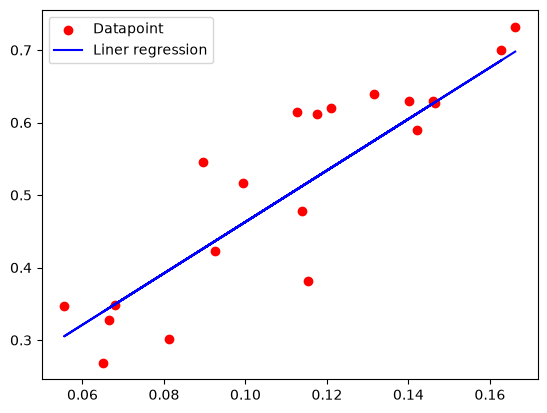

In [10]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [11]:
## Load the Height and weight  to indipendent and dependent variable 

In [12]:
DF2 = pd.read_csv("weight-height.csv")
X = DF2["Height"].values.reshape(-1,1)
X.shape
Y = DF2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [13]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [14]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [15]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)


(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [16]:
for i in range(iterations):
    y_pred = np.dot(X, theta)
    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1}: MSE = {mse}")
    gradient = np.dot(X.T, (y_pred - Y)) / len(Y)
    theta -= learningrate * gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

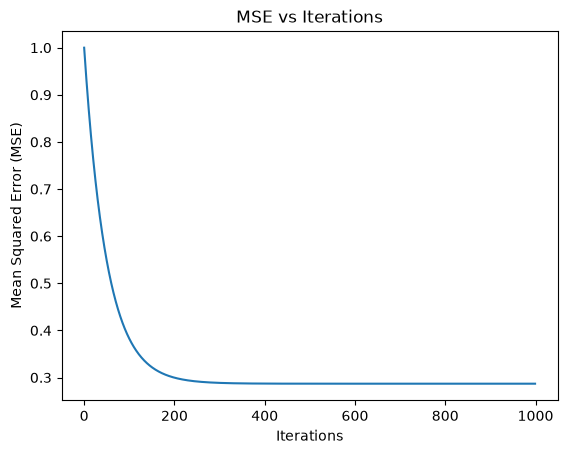

In [17]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

Aim

To develop a Multiple Linear Regression model to predict food delivery time using Distance_km, Preparation_Time_min, Traffic, and Weather as independent variables and Delivery_Time_min as the dependent variable.

Dataset Description

The Food Delivery Times dataset is designed to predict food delivery time based on various influencing factors, such as delivery distance, food preparation time, traffic conditions, and weather conditions.
The dataset contains four independent variables: Distance_km, Preparation_Time_min, Traffic, and Weather. The dependent variable is Delivery_Time_min, which represents the time required to deliver food in minutes.
Traffic and Weather are categorical variables and must be converted into numerical representations using categorical encoding techniques before fitting the regression model.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [5]:
# Load the food delivery dataset from the CSV file
df = pd.read_csv("Food_Delivery_Times.csv")

# Display the first five records
display(df.head())

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column data types and non-null counts
df.info()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


Dataset shape: (1000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB


In [6]:
# Count missing values in every column
print("Missing values:")
print(df.isnull().sum())

# Display descriptive statistics for numerical columns
print("\nStatistical summary:")
display(df.describe())

# Display the frequency of each traffic category
print("\nTraffic Level distribution:")
print(df["Traffic_Level"].value_counts())

# Display the frequency of each weather category
print("\nWeather distribution:")
print(df["Weather"].value_counts())

Missing values:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

Statistical summary:


,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000



Traffic Level distribution:
Traffic_Level
Medium    390
Low       383
High      197
Name: count, dtype: int64

Weather distribution:
Weather
Clear    470
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64


In [7]:
# Keep only the four independent variables and the dependent variable
# Other columns (Order_ID, Time_of_Day, Vehicle_Type, Courier_Experience_yrs) are not used
cols = ["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather", "Delivery_Time_min"]
df_clean = df[cols].copy()

# Count rows that have at least one missing value in the selected columns
print("Rows with missing values:", df_clean.isnull().any(axis=1).sum())

# Traffic_Level and Weather have 30 missing values each
# These are categorical columns, so we remove the incomplete records
# dropna() removes rows with missing values
# reset_index(drop=True) renumbers the rows from 0 again
df_clean = df_clean.dropna().reset_index(drop=True)

# ALTERNATIVE (use instead of dropna if you want to keep all rows):
# Fill missing categories with the most frequent value (mode)
# df_clean["Traffic_Level"] = df_clean["Traffic_Level"].fillna(df_clean["Traffic_Level"].mode()[0])
# df_clean["Weather"] = df_clean["Weather"].fillna(df_clean["Weather"].mode()[0])

Rows with missing values: 60


In [8]:
# Confirm that no missing values remain
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

# Compare the dataset size before and after cleaning
print("\nShape before cleaning:", df.shape)
print("Shape after cleaning :", df_clean.shape)

# Category counts should now add up to the new row count with no NaN
print("\nTraffic Level distribution:")
print(df_clean["Traffic_Level"].value_counts(dropna=False))

print("\nWeather distribution:")
print(df_clean["Weather"].value_counts(dropna=False))

Missing values after cleaning:
Distance_km             0
Preparation_Time_min    0
Traffic_Level           0
Weather                 0
Delivery_Time_min       0
dtype: int64

Shape before cleaning: (1000, 9)
Shape after cleaning : (940, 5)

Traffic Level distribution:
Traffic_Level
Medium    375
Low       374
High      191
Name: count, dtype: int64

Weather distribution:
Weather
Clear    453
Rainy    198
Foggy    102
Snowy     94
Windy     93
Name: count, dtype: int64


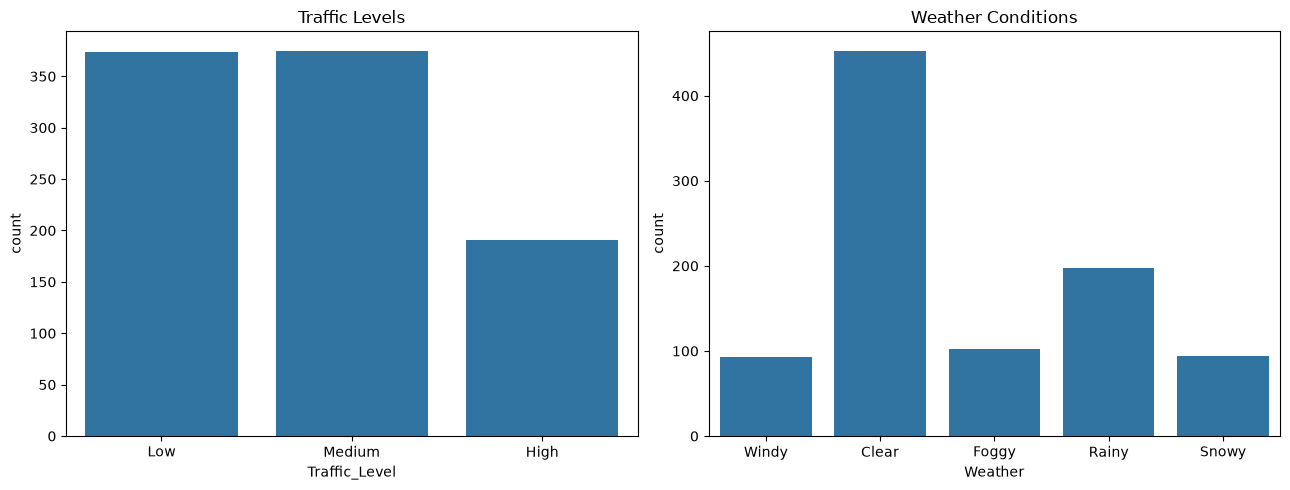

In [9]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart of traffic levels
sns.countplot(data=df_clean, x="Traffic_Level", ax=axes[0])
axes[0].set_title("Traffic Levels")

# Bar chart of weather conditions
sns.countplot(data=df_clean, x="Weather", ax=axes[1])
axes[1].set_title("Weather Conditions")

plt.tight_layout()
plt.show()

In [10]:
# Convert Traffic_Level and Weather into numerical 0/1 columns
# drop_first=True removes one category per column to avoid redundant information
# (the dropped category becomes the reference, e.g. Traffic High, Weather Clear)
df_enc = pd.get_dummies(df_clean, columns=["Traffic_Level", "Weather"], drop_first=True, dtype=float)

display(df_enc.head())
print(df_enc.columns.tolist())

,Distance_km,Preparation_Time_min,Delivery_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,43,1.0,0.0,0.0,0.0,0.0,1.0
1,16.42,20,84,0.0,1.0,0.0,0.0,0.0,0.0
2,9.52,28,59,1.0,0.0,1.0,0.0,0.0,0.0
3,7.44,5,37,0.0,1.0,0.0,1.0,0.0,0.0
4,19.03,16,68,1.0,0.0,0.0,0.0,0.0,0.0


['Distance_km', 'Preparation_Time_min', 'Delivery_Time_min', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']


In [11]:
# X = all input features, Y = target variable (Delivery_Time_min)
X = df_enc.drop(columns="Delivery_Time_min").to_numpy()
Y = df_enc["Delivery_Time_min"].to_numpy()

# Store feature names to label the coefficients later
feature_names = df_enc.drop(columns="Delivery_Time_min").columns.tolist()

print(X.shape)
print(Y.shape)

(940, 8)
(940,)


In [12]:
# 80% training, 20% testing, random_state=42 for a reproducible split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (752, 8) Test: (188, 8)


In [13]:
# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 3.02, 0.98,-11.02,..., 4.53, 9.27, 1.8 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.44
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[197.4 ,154.31, 17.35,..., 8.62, 7.72, 6.55]"


In [14]:
# Predict delivery times for the unseen test data
Y_pred = model.predict(X_test)

mse = mean_squared_error(Y_test, Y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

# Intercept and coefficient of each feature
print("\nIntercept:", model.intercept_)
print(pd.Series(model.coef_, index=feature_names))

MSE : 123.73180027915089
RMSE: 11.123479683945618
MAE : 6.772659346776465
R2  : 0.7453778605148429

Intercept: 13.437805857525426
Distance_km              3.016637
Preparation_Time_min     0.982315
Traffic_Level_Low      -11.023134
Traffic_Level_Medium    -5.349614
Weather_Foggy            6.135415
Weather_Rainy            4.531920
Weather_Snowy            9.269143
Weather_Windy            1.804428
dtype: float64


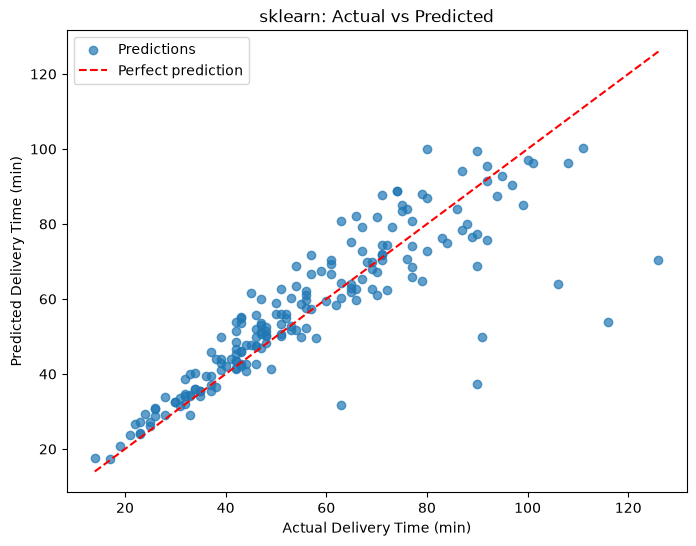

In [15]:
# Actual vs predicted delivery times
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred, alpha=0.7, label="Predictions")

# Reference line: points on it are perfect predictions
lo, hi = Y_test.min(), Y_test.max()
plt.plot([lo, hi], [lo, hi], "--", color="red", label="Perfect prediction")

plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("sklearn: Actual vs Predicted")
plt.legend()
plt.show()

In [16]:
# Mean and std from TRAINING data only, applied to both train and test (no data leakage)
x_mean, x_std = X_train.mean(axis=0), X_train.std(axis=0)
y_mean, y_std = Y_train.mean(), Y_train.std()

Xtr = (X_train - x_mean) / x_std
Xte = (X_test - x_mean) / x_std
Ytr = (Y_train - y_mean) / y_std

In [17]:
# Column of ones so the intercept is learned as theta[0]
Xtr = np.hstack((np.ones((Xtr.shape[0], 1)), Xtr))
Xte = np.hstack((np.ones((Xte.shape[0], 1)), Xte))
print(Xtr.shape, Xte.shape)

(752, 9) (188, 9)


In [18]:
theta = np.zeros(Xtr.shape[1])   # all weights start at zero
iterations = 1000                # number of gradient descent steps
learningrate = 0.1               # step size
mseh = []                        # stores MSE at every iteration

In [19]:
for i in range(iterations):
    # Prediction: y_hat = X . theta
    y_hat = np.dot(Xtr, theta)

    # Store current MSE
    mse_gd = mean_squared_error(Ytr, y_hat)
    mseh.append(mse_gd)

    # Print progress every 100 iterations
    if i % 100 == 0 or i == iterations - 1:
        print(f"Iteration {i+1}: MSE = {mse_gd}")

    # Gradient of MSE with respect to theta, then update the weights
    gradient = np.dot(Xtr.T, (y_hat - Ytr)) / len(Ytr)
    theta -= learningrate * gradient

Iteration 1: MSE = 1.0000000000000002
Iteration 101: MSE = 0.21666391083224937
Iteration 201: MSE = 0.21664331758796415
Iteration 301: MSE = 0.21664329354787398
Iteration 401: MSE = 0.21664329351973136
Iteration 501: MSE = 0.2166432935196984
Iteration 601: MSE = 0.21664329351969847
Iteration 701: MSE = 0.21664329351969838
Iteration 801: MSE = 0.21664329351969838
Iteration 901: MSE = 0.21664329351969838
Iteration 1000: MSE = 0.21664329351969838


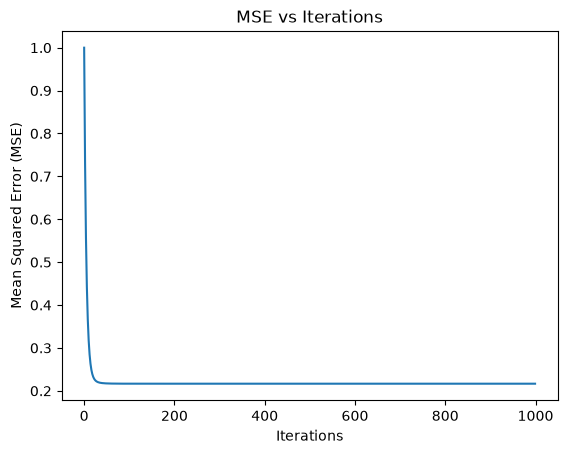

In [20]:
# Curve should fall and flatten out, showing convergence
plt.plot(range(iterations), mseh)
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE vs Iterations")
plt.show()

In [21]:
# Predict on test set, then convert back from Z-score to minutes
Y_pred_gd = np.dot(Xte, theta) * y_std + y_mean

print("MSE :", mean_squared_error(Y_test, Y_pred_gd))
print("RMSE:", mean_squared_error(Y_test, Y_pred_gd) ** 0.5)
print("MAE :", mean_absolute_error(Y_test, Y_pred_gd))
print("R2  :", r2_score(Y_test, Y_pred_gd))

# Both R2 values should be nearly equal
print("\nR2 -> sklearn:", r2_score(Y_test, Y_pred), "| Gradient Descent:", r2_score(Y_test, Y_pred_gd))

MSE : 123.73180027915093
RMSE: 11.12347968394562
MAE : 6.772659346776473
R2  : 0.7453778605148429

R2 -> sklearn: 0.7453778605148429 | Gradient Descent: 0.7453778605148429


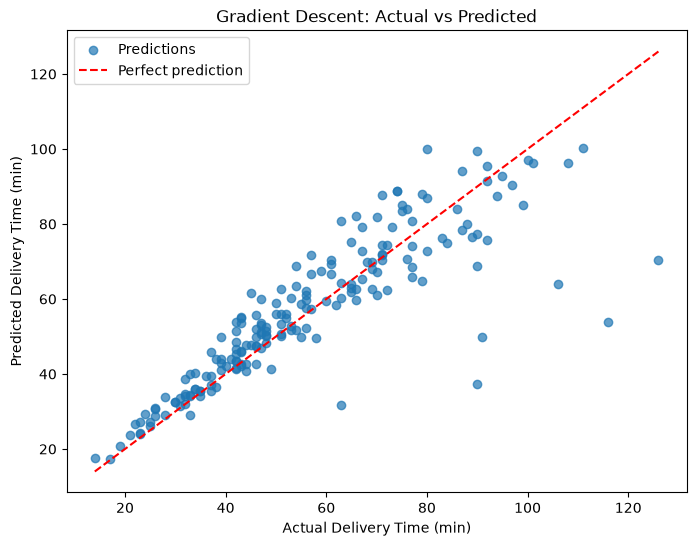

In [22]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, Y_pred_gd, alpha=0.7, label="Predictions")
plt.plot([lo, hi], [lo, hi], "--", color="red", label="Perfect prediction")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Gradient Descent: Actual vs Predicted")
plt.legend()
plt.show()

Conclusion

A Multiple Linear Regression model was built to predict food delivery time using Distance_km, Preparation_Time_min, Traffic_Level and Weather. Missing values in the categorical columns were removed and the categorical features were converted using one-hot encoding. The model was implemented using both scikit-learn and gradient descent from scratch, and both gave identical results (R² = 0.745, MAE = 6.77 min). Distance, preparation time and traffic level were the most influential factors in delivery time.